# Chapter 5 — Forward Position Kinematics

Chapter 4 gave us the homogeneous transformation matrix (HTM): one $4\times4$ matrix that
stores both the **position** and the **orientation** of a frame, and that chains frames
together by plain matrix multiplication. This chapter turns that tool into a
**recipe** that works for *any* serial robot arm:

> **Forward position kinematics:** given the joint variables $\theta_1,\dots,\theta_n$,
> find the pose (position *and* orientation) of the gripper, $\mathbf{T}_e^0$.

The recipe has three steps — set up frames, write one HTM per link, multiply — and we
apply it to five robots of increasing complexity, ending with a real industrial arm
(the UR5e) whose geometry comes straight from a MuJoCo model file.

| Section | Topic |
|---------|-------|
| 5.1 | The general HTM and the six basic HTMs |
| 5.2 | Composition of HTMs, and how a joint moves a frame |
| 5.3 | The three-step forward kinematics procedure |
| 5.4 | Example 1 — planar 2R arm |
| 5.5 | Example 2 — 3R spherical wrist |
| 5.6 | Example 3 — RPP cylindrical robot |
| 5.7 | Example 4 — SCARA robot |
| 5.8 | Example 5 — UR5e from a MuJoCo model |
| 5.9 | The FK Frame Animator and chapter summary |

**Notation used in this chapter.** $\mathbf{T}_C^A$ is the **pose of frame $\{C\}$
relative to frame $\{A\}$**: the subscript names the frame being described, the
superscript names the reference frame. Joint variables are $\theta_i$; for a prismatic
joint we usually write $d_i$ instead, to remind us it is a length.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
import re
from ipywidgets import interact, FloatSlider, IntSlider
from IPython.display import display, Math
%matplotlib inline

np.set_printoptions(precision=4, suppress=True)

## 5.1  The General HTM and the Basic HTMs

### 5.1.1  Reading an HTM column by column

Every HTM has the same block structure. For frame $\{1\}$ described in frame $\{0\}$:

$$
\mathbf{T}_1^0 =
\begin{bmatrix}
n_x & s_x & a_x & d_x\\
n_y & s_y & a_y & d_y\\
n_z & s_z & a_z & d_z\\
0 & 0 & 0 & 1
\end{bmatrix}
=
\begin{bmatrix}
\mathbf{n} & \mathbf{s} & \mathbf{a} & \mathbf{d}\\
0 & 0 & 0 & 1
\end{bmatrix}_{4\times4}
$$

| Column | Meaning |
|--------|---------|
| $\mathbf{n}$ | unit vector along $x_1$, expressed in frame $\{0\}$ |
| $\mathbf{s}$ | unit vector along $y_1$, expressed in frame $\{0\}$ |
| $\mathbf{a}$ | unit vector along $z_1$, expressed in frame $\{0\}$ |
| $\mathbf{d}$ | coordinates of the origin $o_1$, expressed in frame $\{0\}$ |


<p align="center"><img src="Fig5-01_HTM_columns.png" width="620"></p>

<p align="center"><i>Figure 5.1 — The columns of T<sub>1</sub><sup>0</sup> are the axes x<sub>1</sub>, y<sub>1</sub>, z<sub>1</sub> (n, s, a) and the origin o<sub>1</sub> (d), all written in frame {0}.</i></p>

The first three columns form the rotation matrix $\mathbf{R}_1^0$ (orientation); the
last column is the position. So you can **read a frame's pose directly off its HTM**:
column 3 tells you where $z_1$ points, column 4 tells you where $o_1$ is.

### 5.1.2  The six basic HTMs

Almost every HTM we write in this chapter is a product of six **basic HTMs**: a pure
translation along one axis, or a pure rotation about one axis.

**Translation** along $x$, $y$, $z$ by $a$, $b$, $c$:

$$
\mathrm{Trans}_{x,a}=\begin{bmatrix}1&0&0&a\\0&1&0&0\\0&0&1&0\\0&0&0&1\end{bmatrix},\quad
\mathrm{Trans}_{y,b}=\begin{bmatrix}1&0&0&0\\0&1&0&b\\0&0&1&0\\0&0&0&1\end{bmatrix},\quad
\mathrm{Trans}_{z,c}=\begin{bmatrix}1&0&0&0\\0&1&0&0\\0&0&1&c\\0&0&0&1\end{bmatrix}
$$

**Rotation** about $x$, $y$, $z$ by $\alpha$, $\beta$, $\gamma$ (with $c_\alpha=\cos\alpha$, $s_\alpha=\sin\alpha$, etc.):

$$
\mathrm{Rot}_{x,\alpha}=\begin{bmatrix}1&0&0&0\\0&c_\alpha&-s_\alpha&0\\0&s_\alpha&c_\alpha&0\\0&0&0&1\end{bmatrix},\quad
\mathrm{Rot}_{y,\beta}=\begin{bmatrix}c_\beta&0&s_\beta&0\\0&1&0&0\\-s_\beta&0&c_\beta&0\\0&0&0&1\end{bmatrix},\quad
\mathrm{Rot}_{z,\gamma}=\begin{bmatrix}c_\gamma&-s_\gamma&0&0\\s_\gamma&c_\gamma&0&0\\0&0&1&0\\0&0&0&1\end{bmatrix}
$$


<p align="center"><img src="Fig5-02_basic_HTMs.png" width="900"></p>

<p align="center"><i>Figure 5.2 — The six basic HTMs: a pure translation along, or a pure rotation about, one axis.</i></p>

A translation HTM has $\mathbf{I}_{3\times3}$ in the rotation block; a rotation HTM has
the basic rotation matrix from Chapter 4 ($\mathbf{R}_x$, $\mathbf{R}_y$, $\mathbf{R}_z$)
in the rotation block and zero translation.

In [2]:
# ── The six basic HTMs ─────────────────────────────────────────────────────────

def Trans(axis, d):
    # Basic HTM: translate by d along the x, y or z axis.
    T = np.eye(4)
    T['xyz'.index(axis), 3] = d
    return T


def Rot(axis, theta):
    # Basic HTM: rotate by theta (radians) about the x, y or z axis.
    c, s = np.cos(theta), np.sin(theta)
    R = {'x': [[1, 0, 0], [0, c, -s], [0, s, c]],
         'y': [[c, 0, s], [0, 1, 0], [-s, 0, c]],
         'z': [[c, -s, 0], [s, c, 0], [0, 0, 1]]}[axis]
    T = np.eye(4)
    T[:3, :3] = R
    return T


def show(T, name='T'):
    # Print a 4x4 HTM with tidy rounding (no '-0.0').
    print(f'{name} =')
    print(np.round(T, 4) + 0.0)


show(Trans('y', 0.5), 'Trans_y,0.5')
print()
show(Rot('x', np.radians(90)), 'Rot_x,90°')

Trans_y,0.5 =
[[1.  0.  0.  0. ]
 [0.  1.  0.  0.5]
 [0.  0.  1.  0. ]
 [0.  0.  0.  1. ]]

Rot_x,90° =
[[ 1.  0.  0.  0.]
 [ 0.  0. -1.  0.]
 [ 0.  1.  0.  0.]
 [ 0.  0.  0.  1.]]


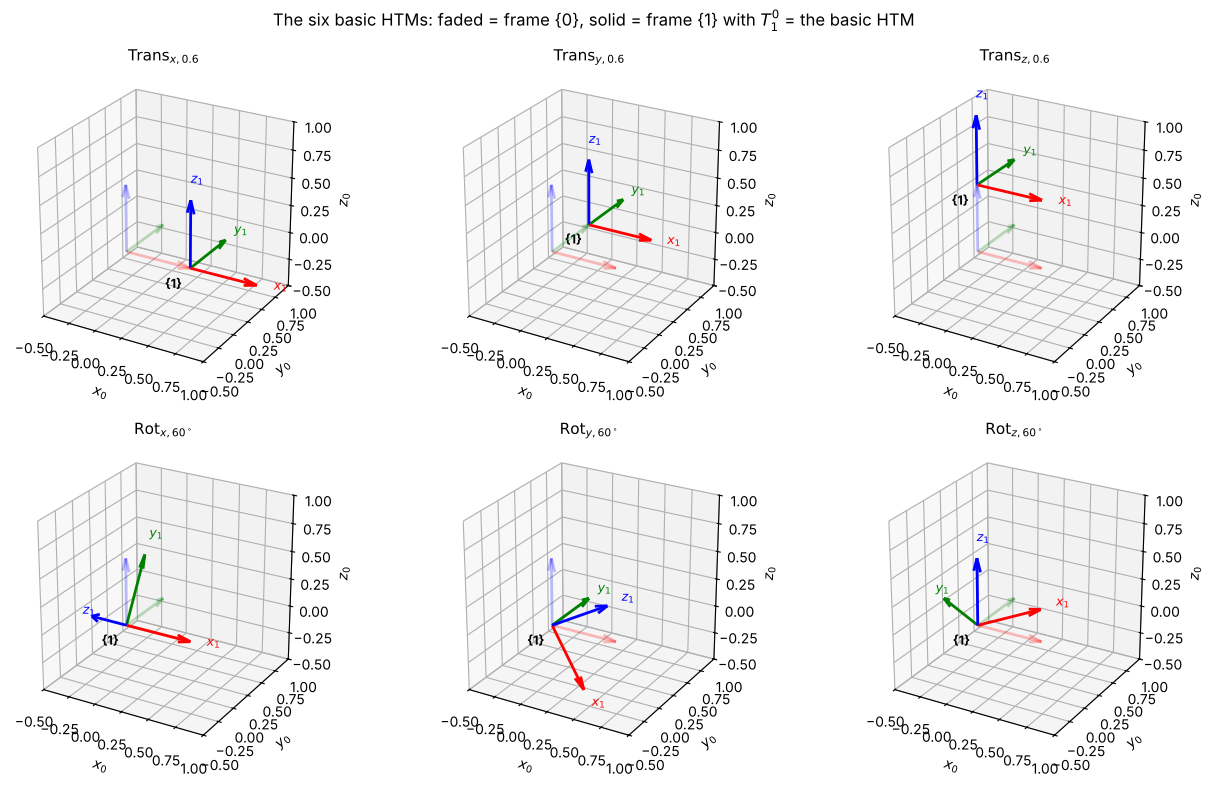

In [3]:
# ── Drawing helpers used throughout the chapter ────────────────────────────────

AXIS_COLORS = ('red', 'green', 'blue')          # x, y, z  (same as Chapter 4)


def draw_frame(ax, T, name='', scale=0.3, alpha=1.0, lw=2.0, axis_labels=True, stack=0):
    # Draw the frame whose pose in frame {0} is the HTM T.
    # stack > 0 shifts the {name} label down, for frames that share an origin.
    o = T[:3, 3]
    for i, col in enumerate(AXIS_COLORS):
        v = T[:3, i] * scale
        ax.quiver(*o, *v, color=col, alpha=alpha, linewidth=lw, arrow_length_ratio=0.2)
        if axis_labels and name and alpha >= 0.5:
            ax.text(*(o + 1.25 * v), f'${"xyz"[i]}_{{{name}}}$', color=col, fontsize=9)
    if name and alpha >= 0.5:
        ax.text(*(o - 0.25 * scale - np.array([0, 0, 0.6 * scale * stack])),
                f'{{{name}}}', fontsize=9, fontweight='bold')


def setup_3d(ax, center=(0, 0, 0), half=1.0, view=(25, -60), title='', zhalf=None):
    # Equal-scale 3D axes centred on `center`; zhalf (optional) shrinks the z-range.
    c = np.asarray(center, float)
    zh = half if zhalf is None else zhalf
    ax.set_xlim(c[0] - half, c[0] + half)
    ax.set_ylim(c[1] - half, c[1] + half)
    ax.set_zlim(c[2] - zh, c[2] + zh)
    ax.set_box_aspect((1, 1, zh / half))
    ax.set_xlabel('$x_0$'); ax.set_ylabel('$y_0$'); ax.set_zlabel('$z_0$')
    ax.view_init(*view)
    if title:
        ax.set_title(title, fontsize=11)


# ── Picture of the six basic HTMs acting on frame {0} ──────────────────────────
basics = [(Trans('x', 0.6), r'$\mathrm{Trans}_{x,0.6}$'),
          (Trans('y', 0.6), r'$\mathrm{Trans}_{y,0.6}$'),
          (Trans('z', 0.6), r'$\mathrm{Trans}_{z,0.6}$'),
          (Rot('x', np.radians(60)), r'$\mathrm{Rot}_{x,60^\circ}$'),
          (Rot('y', np.radians(60)), r'$\mathrm{Rot}_{y,60^\circ}$'),
          (Rot('z', np.radians(60)), r'$\mathrm{Rot}_{z,60^\circ}$')]

fig = plt.figure(figsize=(13, 8))
for i, (T, title) in enumerate(basics):
    ax = fig.add_subplot(2, 3, i + 1, projection='3d')
    draw_frame(ax, np.eye(4), '0', scale=0.6, alpha=0.25)
    draw_frame(ax, T, '1', scale=0.6)
    setup_3d(ax, center=(0.25, 0.25, 0.25), half=0.75, title=title)
fig.suptitle('The six basic HTMs: faded = frame {0}, solid = frame {1} with $T_1^0$ = the basic HTM',
             fontsize=12)
plt.tight_layout(); plt.show()

> **Key Takeaways — Section 5.1**
> - The columns of $\mathbf{T}_1^0 = [\mathbf{n}\ \mathbf{s}\ \mathbf{a}\ \mathbf{d}]$ are the
>   $x_1$, $y_1$, $z_1$ unit vectors and the origin $o_1$, all expressed in frame $\{0\}$.
> - Six basic HTMs — $\mathrm{Trans}_{x}$, $\mathrm{Trans}_{y}$, $\mathrm{Trans}_{z}$,
>   $\mathrm{Rot}_{x}$, $\mathrm{Rot}_{y}$, $\mathrm{Rot}_{z}$ — are the building blocks
>   for every HTM in this chapter.

## 5.2  Composition of HTMs, and How a Joint Moves a Frame

### 5.2.1  Composition

If we know frame $\{B\}$ relative to $\{A\}$ and frame $\{C\}$ relative to $\{B\}$, then

$$\mathbf{T}_C^A = \mathbf{T}_B^A\,\mathbf{T}_C^B .$$

The *inner* indices match and "cancel" ($B$ appears once as a subscript and once as a
superscript), which is an easy way to check that a product is written in the right
order.

### 5.2.2  Reading a product of basic HTMs

A product of basic HTMs can be read **left to right as a sequence of moves of a frame**,
where every move is made along or about the frame's **current** axes (this is the
post-multiplication / body-axis rule from Chapter 4, §4.3.2). For example

$$\mathbf{T}_2^1 = \mathrm{Trans}_{y,1}\;\mathrm{Rot}_{z,90^\circ}\;\mathrm{Rot}_{y,90^\circ}$$

means: start at frame $\{1\}$, slide 1 along $y$, then rotate $90^\circ$ about the
*new* $z$, then rotate $90^\circ$ about the *newest* $y$. Where the frame ends up is
frame $\{2\}$.


<p align="center"><img src="Fig5-03_reading_product_of_HTMs.png" width="900"></p>

<p align="center"><i>Figure 5.3 — Reading T<sub>2</sub><sup>1</sup> = Trans<sub>y,1</sub> Rot<sub>z,90°</sub> Rot<sub>y,90°</sub> left to right: each move uses the frame’s current axes.</i></p>

### 5.2.3  Worked example (Lecture 8)

Frame $\{1\}$ sits 1 unit above the ground frame $\{0\}$ with the same orientation, and
frame $\{2\}$ is obtained from frame $\{1\}$ by the three moves above:

$$\mathbf{T}_1^0 = \mathrm{Trans}_{z,1}, \qquad
\mathbf{T}_2^1 = \mathrm{Trans}_{y,1}\,\mathrm{Rot}_{z,90^\circ}\,\mathrm{Rot}_{y,90^\circ}
= \begin{bmatrix}0&-1&0&0\\0&0&1&1\\-1&0&0&0\\0&0&0&1\end{bmatrix}.$$


<p align="center"><img src="Fig5-04_composition_example.png" width="460"></p>

<p align="center"><i>Figure 5.4 — Lecture 8 example: frame {1} is 1 above {0}; frame {2} is reached by the moves of Figure 5.3; q is 1 along z<sub>2</sub>.</i></p>

A point $q$ sits 1 unit along $z_2$: $q^2 = (0,0,1)$. Where is it in frame $\{0\}$?
Augment with a 1 and multiply:

$$\begin{bmatrix}q^0\\1\end{bmatrix} = \mathbf{T}_2^0\begin{bmatrix}q^2\\1\end{bmatrix},
\qquad \mathbf{T}_2^0 = \mathbf{T}_1^0\,\mathbf{T}_2^1 .$$

In [4]:
T10 = Trans('z', 1)
T21 = Trans('y', 1) @ Rot('z', np.radians(90)) @ Rot('y', np.radians(90))
T20 = T10 @ T21                          # composition: inner indices '1' cancel

show(T21, 'T_2^1')
print()
show(T20, 'T_2^0')

q2 = np.array([0, 0, 1, 1])              # q in frame {2}, augmented with a 1
q1 = T21 @ q2
q0 = T20 @ q2
print('\nq^2 =', q2[:3], '  q^1 =', q1[:3], '  q^0 =', q0[:3])
print('Matches the lecture result q^0 = (0, 2, 1)?', np.allclose(q0[:3], [0, 2, 1]))

T_2^1 =
[[ 0. -1.  0.  0.]
 [ 0.  0.  1.  1.]
 [-1.  0.  0.  0.]
 [ 0.  0.  0.  1.]]

T_2^0 =
[[ 0. -1.  0.  0.]
 [ 0.  0.  1.  1.]
 [-1.  0.  0.  1.]
 [ 0.  0.  0.  1.]]

q^2 = [0 0 1]   q^1 = [0. 2. 0.]   q^0 = [0. 2. 1.]
Matches the lecture result q^0 = (0, 2, 1)? True


Below, the slider applies the factors of $\mathbf{T}_2^0 = \mathrm{Trans}_{z,1}\cdot
\mathrm{Trans}_{y,1}\,\mathrm{Rot}_{z,90^\circ}\,\mathrm{Rot}_{y,90^\circ}$ one at a time.
The bold frame with a black dot is the **moving frame** after the factors applied so
far; faded frames are earlier intermediate stops, and a labeled frame appears each time
a $\mathbf{T}_i^{i-1}$ is complete. Watch how each rotation acts about the
moving frame's *current* axis.

The two helper functions in the next cell are reused for every robot in this chapter.
A product is stored as a list of **groups** — one group per $\mathbf{T}_i^{i-1}$ — and
each group is a list of basic-HTM **factors**.

In [5]:
# ── Factors and chains: a product of basic HTMs, stored so we can step through it ─

def Tr(axis, val, tex):
    # One translation factor; tex is the LaTeX for the amount, e.g. 'L_1'.
    return dict(kind='trans', axis=axis, val=val, tex=rf'\mathrm{{Trans}}_{{{axis},{tex}}}')


def Rt(axis, val, tex):
    # One rotation factor (val in radians); tex is the LaTeX for the angle.
    return dict(kind='rot', axis=axis, val=val, tex=rf'\mathrm{{Rot}}_{{{axis},{tex}}}')


def factor_T(f):
    return Trans(f['axis'], f['val']) if f['kind'] == 'trans' else Rot(f['axis'], f['val'])


def chain_frames(groups):
    # groups = [(frame name, [factors]), ...]  ->  {frame name: T^0 of that frame}
    T, frames = np.eye(4), {'0': np.eye(4)}
    for name, factors in groups:
        for f in factors:
            T = T @ factor_T(f)
        frames[name] = T
    return frames


def product_latex(groups, k, lhs):
    # LaTeX for the whole product, with the factors not yet applied shown in grey.
    out, j = [], 0
    for _, factors in groups:
        for f in factors:
            out.append(f['tex'] if j < k else r'{\color{lightgray}' + f['tex'] + '}')
            j += 1
    return lhs + ' = ' + r'\,'.join(out)


def plot_chain(ax, groups, k=None, scale=0.25, skeleton=True, axis_labels=True, **setup_kw):
    # Draw the frames of a chain. If k is given, show only the first k factors applied
    # (faded frames = intermediate stops, black dot = the moving frame).
    flat = [(name, f) for name, factors in groups for f in factors]
    N = len(flat)
    k = N if k is None else k
    ends = np.cumsum([len(fs) for _, fs in groups])       # factor count at each frame
    names = [name for name, _ in groups]

    if skeleton:                                           # links: polyline through origins
        pts = np.array([T[:3, 3] for T in chain_frames(groups).values()])
        ax.plot(*pts.T, color='0.5', lw=6, alpha=1.0 if k == N else 0.25,
                solid_capstyle='round', zorder=0)
        ax.scatter(*pts[:-1].T, color='0.25', s=40, alpha=1.0 if k == N else 0.25)

    seen = {}                                              # frames sharing an origin

    def n_before(T):
        key = tuple(np.round(T[:3, 3], 3))
        seen[key] = seen.get(key, -1) + 1
        return seen[key]

    draw_frame(ax, np.eye(4), '0', scale=scale * 1.3, axis_labels=axis_labels, stack=n_before(np.eye(4)))
    T = np.eye(4)
    for j in range(k):
        T = T @ factor_T(flat[j][1])
        if j + 1 in ends:                                   # a T_i^{i-1} is complete
            n = n_before(T)                                 # shorter arrows if origin is shared
            draw_frame(ax, T, names[list(ends).index(j + 1)], scale=scale * max(0.55, 1 - 0.15 * n),
                       axis_labels=axis_labels, stack=n)
        elif j == k - 1:                                    # the moving frame right now: bold
            draw_frame(ax, T, scale=scale, lw=3)
        else:                                               # an earlier intermediate stop: faded
            draw_frame(ax, T, scale=scale * 0.8, alpha=0.3, lw=1)
    if k < N:                                               # mark the moving frame
        ax.scatter(*T[:3, 3], color='black', s=25, zorder=5)
    setup_3d(ax, **setup_kw)
    return T, N


# ── Step through the Lecture 8 example ─────────────────────────────────────────
groups_L8 = [('1', [Tr('z', 1, '1')]),
             ('2', [Tr('y', 1, '1'), Rt('z', np.pi / 2, r'90^\circ'), Rt('y', np.pi / 2, r'90^\circ')])]


def step_L8(k):
    fig = plt.figure(figsize=(6.5, 6))
    ax = fig.add_subplot(111, projection='3d')
    T, N = plot_chain(ax, groups_L8, k, scale=0.35, center=(0, 0.6, 0.6), half=1.0)
    q0 = (chain_frames(groups_L8)['2'] @ np.array([0, 0, 1, 1]))[:3]
    if k == N:
        ax.scatter(*q0, color='purple', s=60)
        ax.text(*(q0 + 0.08), '$q$', color='purple', fontsize=12)
    plt.show()
    display(Math(product_latex(groups_L8, k, r'\mathbf{T}_2^0')))
    show(T, f'Product of the first {k} factor(s)')


interact(step_L8, k=IntSlider(value=4, min=0, max=4, description='factors'));

interactive(children=(IntSlider(value=4, description='factors', max=4), Output()), _dom_classes=('widget-inter…

### 5.2.4  How a joint moves a frame (Lecture 8)

Now attach frame $\{1\}$ to a link that turns on a revolute joint whose axis is $z_0$.
At the **home configuration** ($\theta = 0$) the frame is $\mathbf{T}_1^0$. When the
joint turns by $\theta$, the link — and the frame glued to it — rotates about the joint
axis to a new frame $\{1'\}$:

$$\mathbf{T}_{1'}^0 = \mathbf{T}_1^0\,\mathbf{T}_{1'}^1 = \mathbf{T}_1^0\,\mathrm{Rot}_{z,\theta}.$$


<p align="center"><img src="Fig5-05_joint_moves_frame.png" width="440"></p>

<p align="center"><i>Figure 5.5 — A revolute joint about z<sub>1</sub> turns frame {1} into {1′}: post-multiply by Rot<sub>z,θ</sub>.</i></p>

This only works as a single post-multiplied $\mathrm{Rot}_{z,\theta}$ because we chose
$z_1$ to lie **along the joint axis**: rotating about the joint axis is then the same
as rotating about the frame's own current $z$-axis. That choice is the key idea of the
whole procedure in Section 5.3.

> **Key Takeaways — Section 5.2**
> - Compose frames by multiplying HTMs: $\mathbf{T}_C^A = \mathbf{T}_B^A\,\mathbf{T}_C^B$ (inner indices cancel).
> - Read a product of basic HTMs left to right: each factor moves the frame along or about its **current** axes.
> - Augment a point with a 1 to transform it: $[q^0;1] = \mathbf{T}_2^0\,[q^2;1]$.
> - If $z_i$ lies along joint $i$'s axis, turning the joint by $\theta$ just post-multiplies the frame by $\mathrm{Rot}_{z,\theta}$.

## 5.3  The Forward Kinematics Procedure

For an $n$-joint robotic arm:

**Step 1 — Set up a frame for each link.**
- Frame $\{0\}$: fixed to the ground (the inertial frame).
- Frames $\{1\},\dots,\{n\}$: frame $\{i\}$ is fixed to link $i$ and moves with joint $i$.
  Put **$z_i$ along the axis of joint $i$** (the rotation axis for a revolute joint,
  the sliding direction for a prismatic joint).
- Frame $\{e\}$: at the gripper (end-effector) center. Because there is no joint between
  frame $\{n\}$ and frame $\{e\}$, $\mathbf{T}_e^n$ is **constant**.


<p align="center"><img src="Fig5-06_FK_procedure.png" width="560"></p>

<p align="center"><i>Figure 5.6 — Step 1: frame {0} on the ground, frame {i} on link i with z<sub>i</sub> along joint i, frame {e} at the gripper.</i></p>

**Step 2 — Obtain $\mathbf{T}_i^{i-1}(\theta_i)$ for $i = 1,\dots,n$.**
- *Home configuration* ($\theta_i = 0$ for all $i$): write $\mathbf{T}_i^{i-1}(0)$ as a
  product of basic HTMs that moves frame $\{i-1\}$ onto frame $\{i\}$.
- *Joint motion* ($\theta_i \neq 0$): post-multiply by one basic HTM along/about $z_i$:

$$
\boxed{
\begin{aligned}
\text{revolute joint:}\quad & \mathbf{T}_i^{i-1}(\theta_i) = \mathbf{T}_i^{i-1}(0)\,\mathrm{Rot}_{z,\theta_i}\\
\text{prismatic joint:}\quad & \mathbf{T}_i^{i-1}(\theta_i) = \mathbf{T}_i^{i-1}(0)\,\mathrm{Trans}_{z,\theta_i}
\end{aligned}}
$$

**Step 3 — Multiply.**

$$\boxed{\mathbf{T}_e^0 = \mathbf{T}_1^0(\theta_1)\,\mathbf{T}_2^1(\theta_2)\cdots\mathbf{T}_n^{n-1}(\theta_n)\,\mathbf{T}_e^n}$$

The position of the gripper is the last column of $\mathbf{T}_e^0$; its orientation is
the upper-left $3\times3$ block.

> **Note for readers of other textbooks.** Many books use the Denavit–Hartenberg (DH)
> convention, which restricts how frames may be placed so that each link needs exactly
> four parameters. Our procedure lets you place frames freely (only $z_i$ along joint
> $i$ is required) and writes $\mathbf{T}_i^{i-1}(0)$ with any basic HTMs you like. Both
> give the same $\mathbf{T}_e^0$; ours is easier to set up from a drawing or a CAD/MJCF
> model.

The class below is a direct translation of Steps 2 and 3 into code. Each example
in this chapter only has to supply the **home factors** of every $\mathbf{T}_i^{i-1}(0)$,
the **joint types**, and the constant **tool factors** of $\mathbf{T}_e^n$.

In [6]:
class Robot:
    # A serial arm described by the three-step FK procedure.
    #   home   : home[i] = list of factors whose product is T_{i+1}^{i}(0)
    #   joints : list of (slider label, LaTeX symbol, 'R' or 'P', (min, max))
    #   tool   : list of factors whose product is the constant T_e^n

    def __init__(self, name, home, joints, tool):
        self.name, self.home, self.joints, self.tool = name, home, joints, tool

    def groups(self, q):
        # Step 2: T_i^{i-1}(q_i) = T_i^{i-1}(0) * Rot_z,q_i  (or Trans_z,q_i)
        G = []
        for i, (_, tex, jtype, _) in enumerate(self.joints):
            motion = Rt('z', q[i], tex) if jtype == 'R' else Tr('z', q[i], tex)
            G.append((str(i + 1), self.home[i] + [motion]))
        G.append(('e', self.tool))
        return G

    def frames(self, q):
        return chain_frames(self.groups(q))       # every frame's T^0

    def fk(self, q):
        return self.frames(q)['e']                 # Step 3: T_e^0


def explore(robot, figsize=(7, 6.5), **setup_kw):
    # Interactive view: one slider per joint, plus a slider that steps through the product.
    sliders = {}
    for i, (label, _, jtype, (lo, hi)) in enumerate(robot.joints):
        unit = ' (°)' if jtype == 'R' else ''
        sliders[f'q{i}'] = FloatSlider(value=0, min=lo, max=hi, step=1 if jtype == 'R' else 0.01,
                                      description=label + unit)
    N = sum(len(fs) for _, fs in robot.groups(np.zeros(len(robot.joints))))
    sliders['k'] = IntSlider(value=N, min=0, max=N, description='factors')

    def _view(k, **qs):
        q = [np.radians(qs[f'q{i}']) if j[2] == 'R' else qs[f'q{i}']
             for i, j in enumerate(robot.joints)]
        G = robot.groups(q)
        fig = plt.figure(figsize=figsize)
        ax = fig.add_subplot(111, projection='3d')
        T, _ = plot_chain(ax, G, k, title=robot.name, **setup_kw)
        plt.show()
        display(Math(product_latex(G, k, r'\mathbf{T}_e^0')))
        show(T, 'T_e^0' if k == N else f'Product of the first {k} factor(s)')

    interact(_view, **sliders)


def snapshot(robot, poses, titles, figsize=(13, 5.5), **setup_kw):
    # Static side-by-side pictures of the robot at a few joint vectors (radians / metres).
    fig = plt.figure(figsize=figsize)
    for i, (q, t) in enumerate(zip(poses, titles)):
        ax = fig.add_subplot(1, len(poses), i + 1, projection='3d')
        plot_chain(ax, robot.groups(q), title=t, **setup_kw)
    plt.tight_layout(); plt.show()

In [7]:
# ── SymPy versions of the basic HTMs, for closed-form FK ───────────────────────

def sTrans(axis, d):
    T = sp.eye(4)
    T['xyz'.index(axis), 3] = d
    return T


def sRot(axis, t):
    c, s = sp.cos(t), sp.sin(t)
    R = {'x': [[1, 0, 0], [0, c, -s], [0, s, c]],
         'y': [[c, 0, s], [0, 1, 0], [-s, 0, c]],
         'z': [[c, -s, 0], [s, c, 0], [0, 0, 1]]}[axis]
    T = sp.eye(4)
    T[:3, :3] = sp.Matrix(R)
    return T


def show_sym(T, lhs):
    # Display a symbolic matrix using the shorthand c_1 = cos(theta_1), s_12 = sin(theta_1+theta_2), ...
    tex = sp.latex(T)

    def short(m):
        fn, inner = m.group(1), m.group(2)
        idx = re.findall(r'\\theta_\{(\d)\}', inner)
        rest = re.sub(r'\\theta_\{\d\}|\+|\s', '', inner)
        return f'{fn[0]}_{{{"".join(idx)}}}' if idx and not rest else m.group(0)

    tex = re.sub(r'\\(cos|sin)\{\\left\((.*?)\\right\)\}', short, tex)
    display(Math(lhs + ' = ' + tex))

> **Key Takeaways — Section 5.3**
> - **Step 1:** frame $\{0\}$ on the ground, frame $\{i\}$ on link $i$ with $z_i$ along joint $i$, frame $\{e\}$ at the gripper.
> - **Step 2:** write the home transform $\mathbf{T}_i^{i-1}(0)$ from basic HTMs, then post-multiply by $\mathrm{Rot}_{z,\theta_i}$ (revolute) or $\mathrm{Trans}_{z,\theta_i}$ (prismatic).
> - **Step 3:** $\mathbf{T}_e^0 = \mathbf{T}_1^0\mathbf{T}_2^1\cdots\mathbf{T}_n^{n-1}\mathbf{T}_e^n$.
> - The same three steps work for any serial robot, from a 2R arm to a 6-DOF industrial arm.

## 5.4  Example 1 — Planar 2R Arm

Two revolute joints with parallel axes (out of the page), link lengths $L_1$ and $L_2$.
This is the Chapter 3 robot, so we already know the answer — a good first test of the
procedure.

**Step 1 — Frames.** All $z$-axes point out of the page (along the joint axes). At home
the arm is stretched along $x_0$: frame $\{1\}$ coincides with $\{0\}$, frame $\{2\}$ is
at the elbow, frame $\{e\}$ at the tip. All frames stay parallel at home.


<p align="center"><img src="Fig5-07_2R_frames.png" width="820"></p>

<p align="center"><i>Figure 5.7 — Example 1 (Lecture 9): frames of the planar 2R arm at home (a) and after the joints move (b).</i></p>

**Step 2 — Home configuration and joint motion.**

$$\mathbf{T}_1^0(0) = \mathbf{I}_{4\times4},\qquad
\mathbf{T}_2^1(0) = \mathrm{Trans}_{x,L_1},\qquad
\mathbf{T}_e^2 = \mathrm{Trans}_{x,L_2}$$

$$\mathbf{T}_1^0(\theta_1) = \mathbf{T}_1^0(0)\,\mathrm{Rot}_{z,\theta_1} = \mathrm{Rot}_{z,\theta_1},\qquad
\mathbf{T}_2^1(\theta_2) = \mathbf{T}_2^1(0)\,\mathrm{Rot}_{z,\theta_2} = \mathrm{Trans}_{x,L_1}\mathrm{Rot}_{z,\theta_2}$$

**Step 3 — Multiply.**

$$\mathbf{T}_e^0 = \mathbf{T}_1^0(\theta_1)\,\mathbf{T}_2^1(\theta_2)\,\mathbf{T}_e^2
= \mathrm{Rot}_{z,\theta_1}\,\mathrm{Trans}_{x,L_1}\,\mathrm{Rot}_{z,\theta_2}\,\mathrm{Trans}_{x,L_2}$$

Read it left to right: turn by $\theta_1$, walk $L_1$, turn by $\theta_2$, walk $L_2$.

In [8]:
L1, L2 = 1.0, 0.7


def fk_2R(th1, th2, L1=1.0, L2=0.7):
    # Step 2 — home configuration (θ = 0)
    T10_0 = np.eye(4)                       # T_1^0(0)
    T21_0 = Trans('x', L1)                  # T_2^1(0)
    Te2   = Trans('x', L2)                  # T_e^2 (constant)
    # Step 2 — joint motion
    T10 = T10_0 @ Rot('z', th1)             # revolute joint 1
    T21 = T21_0 @ Rot('z', th2)             # revolute joint 2
    # Step 3
    return T10 @ T21 @ Te2


th1, th2 = np.radians(90), np.radians(-90)
Te0 = fk_2R(th1, th2)
show(Te0, 'T_e^0 at (θ1, θ2) = (90°, -90°)')

# Compare with the Chapter 3 trigonometry
x = L1*np.cos(th1) + L2*np.cos(th1 + th2)
y = L1*np.sin(th1) + L2*np.sin(th1 + th2)
print(f'\nChapter 3 formula: (x, y) = ({x:.4f}, {y:.4f})   matches column 4? {np.allclose(Te0[:2, 3], [x, y])}')

T_e^0 at (θ1, θ2) = (90°, -90°) =
[[1.  0.  0.  0.7]
 [0.  1.  0.  1. ]
 [0.  0.  1.  0. ]
 [0.  0.  0.  1. ]]

Chapter 3 formula: (x, y) = (0.7000, 1.0000)   matches column 4? True


In [9]:
# Closed form with SymPy
t1, t2, l1, l2 = sp.symbols('theta_1 theta_2 L_1 L_2', real=True)
Te0_2R = sp.simplify(sRot('z', t1) * sTrans('x', l1) * sRot('z', t2) * sTrans('x', l2))
show_sym(Te0_2R, r'\mathbf{T}_e^0')

<IPython.core.display.Math object>

with $c_1 = \cos\theta_1$, $s_1 = \sin\theta_1$, $c_{12} = \cos(\theta_1+\theta_2)$,
$s_{12} = \sin(\theta_1+\theta_2)$. The last column is exactly the Chapter 3 result
$x = L_1c_1 + L_2c_{12}$, $y = L_1s_1 + L_2s_{12}$ — and we get the orientation
(a rotation of $\theta_1+\theta_2$ about $z$) for free.

Robot.fk matches fk_2R: True


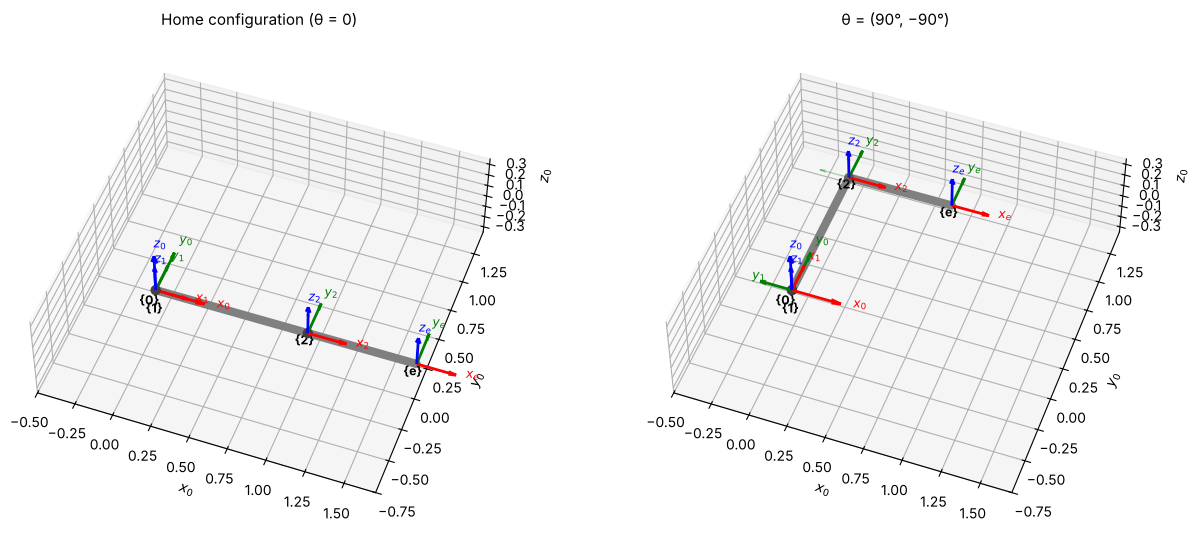

In [10]:
robot_2R = Robot('Example 1: planar 2R',
                 home=[[], [Tr('x', L1, 'L_1')]],
                 joints=[('θ₁', r'\theta_1', 'R', (-180, 180)),
                         ('θ₂', r'\theta_2', 'R', (-180, 180))],
                 tool=[Tr('x', L2, 'L_2')])

view_2R = dict(center=(0.6, 0.35, 0), half=1.1, zhalf=0.35, view=(50, -70))

# Generic Robot class agrees with the hand-written fk_2R?
q_test = np.radians([37, -112])
print('Robot.fk matches fk_2R:', np.allclose(robot_2R.fk(q_test), fk_2R(*q_test)))

snapshot(robot_2R, [np.zeros(2), np.radians([90, -90])],
         ['Home configuration (θ = 0)', 'θ = (90°, −90°)'], **view_2R)

In [11]:
explore(robot_2R, **view_2R)

interactive(children=(IntSlider(value=4, description='factors', max=4), FloatSlider(value=0.0, description='θ₁…

> **Key Takeaways — Section 5.4**
> - $\mathbf{T}_e^0 = \mathrm{Rot}_{z,\theta_1}\mathrm{Trans}_{x,L_1}\mathrm{Rot}_{z,\theta_2}\mathrm{Trans}_{x,L_2}$: "turn, walk, turn, walk".
> - The position column reproduces the Chapter 3 formula; the rotation block adds the orientation $\theta_1+\theta_2$.

## 5.5  Example 2 — 3R Spherical Wrist

Three revolute joints whose axes **all meet at one point** (the wrist center): roll,
pitch, roll. A gripper sits a distance $L$ beyond the wrist center along the last axis.

**Step 1 — Frames.** Put every $z_i$ along joint $i$. Because the axes intersect, all
three origins are at the wrist center: $o_0 = o_1 = o_2 = o_3$. At home, $z_1$ and $z_3$
point up (along $z_0$) and $z_2$ points along $y_0$, the pitch axis.


<p align="center"><img src="Fig5-08_spherical_wrist.png" width="620"></p>

<p align="center"><i>Figure 5.8 — Example 2 (Lecture 9): the spherical wrist. All joint axes meet at the wrist center.</i></p>

**Step 2 — Home configuration and joint motion.**

$$\mathbf{T}_1^0(0) = \mathbf{I}_{4\times4},\qquad
\mathbf{T}_2^1(0) = \mathrm{Rot}_{x,-90^\circ},\qquad
\mathbf{T}_3^2(0) = \mathrm{Rot}_{x,90^\circ},\qquad
\mathbf{T}_e^3 = \mathrm{Trans}_{z,L}$$

$\mathrm{Rot}_{x,-90^\circ}$ tips $z$ over so that $z_2$ lies along the pitch axis, and
$\mathrm{Rot}_{x,90^\circ}$ tips it back up for the third (roll) joint. Then

$$\mathbf{T}_1^0(\theta_1) = \mathrm{Rot}_{z,\theta_1},\quad
\mathbf{T}_2^1(\theta_2) = \mathrm{Rot}_{x,-90^\circ}\mathrm{Rot}_{z,\theta_2},\quad
\mathbf{T}_3^2(\theta_3) = \mathrm{Rot}_{x,90^\circ}\mathrm{Rot}_{z,\theta_3}.$$

**Step 3 — Multiply.**

$$\mathbf{T}_e^0 = \mathrm{Rot}_{z,\theta_1}\;\mathrm{Rot}_{x,-90^\circ}\mathrm{Rot}_{z,\theta_2}\;\mathrm{Rot}_{x,90^\circ}\mathrm{Rot}_{z,\theta_3}\;\mathrm{Trans}_{z,L}$$

In [12]:
L = 0.6


def fk_wrist(th1, th2, th3, L=0.6):
    # Step 2 — home configuration (θ = 0)
    T10_0 = np.eye(4)                       # T_1^0(0)
    T21_0 = Rot('x', np.radians(-90))       # T_2^1(0)
    T32_0 = Rot('x', np.radians(90))        # T_3^2(0)
    Te3   = Trans('z', L)                   # T_e^3 (constant)
    # Step 2 — joint motion (all revolute)
    T10 = T10_0 @ Rot('z', th1)
    T21 = T21_0 @ Rot('z', th2)
    T32 = T32_0 @ Rot('z', th3)
    # Step 3
    return T10 @ T21 @ T32 @ Te3


show(fk_wrist(0, np.radians(90), 0), 'T_e^0 at (θ1, θ2, θ3) = (0, 90°, 0)')

T_e^0 at (θ1, θ2, θ3) = (0, 90°, 0) =
[[ 0.   0.   1.   0.6]
 [ 0.   1.   0.   0. ]
 [-1.   0.   0.   0. ]
 [ 0.   0.   0.   1. ]]


In [13]:
t1, t2, t3, Ls = sp.symbols('theta_1 theta_2 theta_3 L', real=True)
Te0_wrist = sp.simplify(sRot('z', t1) * sRot('x', -sp.pi/2) * sRot('z', t2)
                        * sRot('x', sp.pi/2) * sRot('z', t3) * sTrans('z', Ls))
show_sym(Te0_wrist, r'\mathbf{T}_e^0')

# The middle three factors are just a rotation about y:
middle = sp.simplify(sRot('x', -sp.pi/2) * sRot('z', t2) * sRot('x', sp.pi/2))
print('Rot_x,-90 · Rot_z,θ2 · Rot_x,90  ==  Rot_y,θ2 ?', sp.simplify(middle - sRot('y', t2)) == sp.zeros(4))

<IPython.core.display.Math object>

Rot_x,-90 · Rot_z,θ2 · Rot_x,90  ==  Rot_y,θ2 ? True


Two things to notice:

- The gripper position is $o_e = L\,(c_1s_2,\ s_1s_2,\ c_2)$ — a point on a sphere of
  radius $L$, which is why this is called a *spherical* wrist. $\theta_3$ does not move
  the gripper's position at all; it only spins the gripper about its own axis.
- $\mathrm{Rot}_{x,-90^\circ}\mathrm{Rot}_{z,\theta_2}\mathrm{Rot}_{x,90^\circ} =
  \mathrm{Rot}_{y,\theta_2}$, so the orientation is
  $\mathbf{R}_e^0 = \mathbf{R}_z(\theta_1)\mathbf{R}_y(\theta_2)\mathbf{R}_z(\theta_3)$ —
  exactly the **ZYZ Euler angles**. A spherical wrist can reach any orientation, which is
  why most 6-DOF arms end with one.

Robot.fk matches fk_wrist: True


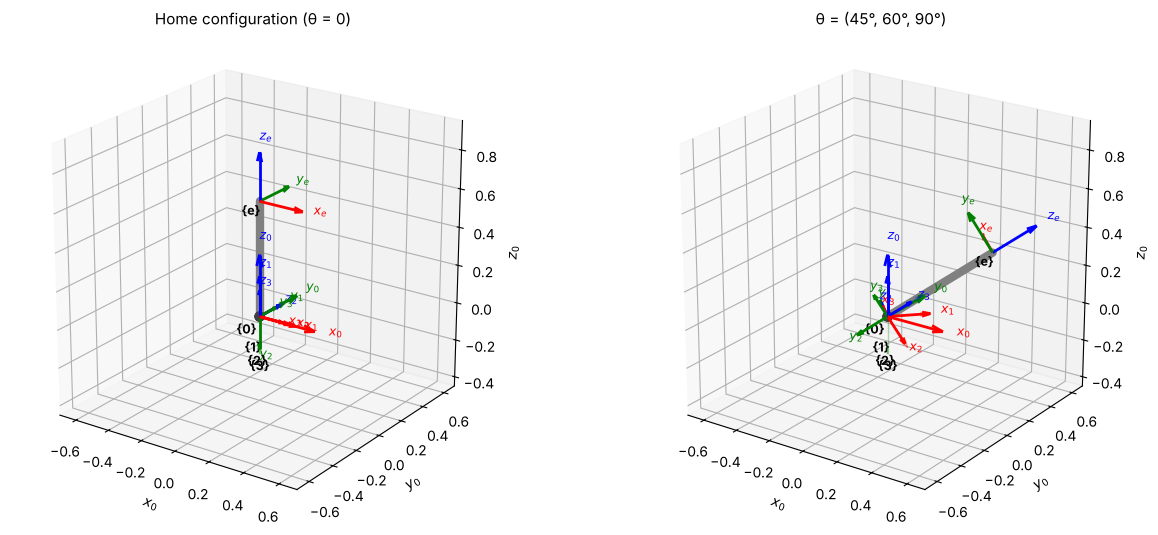

In [14]:
robot_wrist = Robot('Example 2: spherical wrist (roll–pitch–roll)',
                    home=[[], [Rt('x', -np.pi/2, r'-90^\circ')], [Rt('x', np.pi/2, r'90^\circ')]],
                    joints=[('θ₁', r'\theta_1', 'R', (-180, 180)),
                            ('θ₂', r'\theta_2', 'R', (-180, 180)),
                            ('θ₃', r'\theta_3', 'R', (-180, 180))],
                    tool=[Tr('z', L, 'L')])

view_wrist = dict(center=(0, 0, 0.25), half=0.7, view=(22, -55))
q_test = np.radians([20, -50, 75])
print('Robot.fk matches fk_wrist:', np.allclose(robot_wrist.fk(q_test), fk_wrist(*q_test)))

snapshot(robot_wrist, [np.zeros(3), np.radians([45, 60, 90])],
         ['Home configuration (θ = 0)', 'θ = (45°, 60°, 90°)'], **view_wrist)

In [15]:
explore(robot_wrist, **view_wrist)

interactive(children=(IntSlider(value=6, description='factors', max=6), FloatSlider(value=0.0, description='θ₁…

> **Key Takeaways — Section 5.5**
> - When joint axes intersect, several frames share one origin; the home transforms are then pure rotations.
> - Fixed rotations in $\mathbf{T}_i^{i-1}(0)$ (here $\mathrm{Rot}_{x,\mp90^\circ}$) exist only to point $z_i$ along joint $i$.
> - Spherical wrist: position $L(c_1s_2, s_1s_2, c_2)$, orientation $\mathbf{R}_z\mathbf{R}_y\mathbf{R}_z$ (ZYZ Euler angles).

## 5.6  Example 3 — RPP Cylindrical Robot

A revolute base $\theta_1$, a prismatic vertical lift $d_2$, and a prismatic horizontal
reach $d_3$. The shoulder is at height $h$ and the reach slide starts a distance $a$
from the column.

**Step 1 — Frames.** $z_1$ along the base axis (up). $z_2$ along the lift direction (up),
at height $h$. $z_3$ along the reach direction, which at home is $x_0$; the gripper is at
the end of the reach slide, so frame $\{e\}$ coincides with frame $\{3\}$.


<p align="center"><img src="Fig5-09_RPP_cylindrical.png" width="520"></p>

<p align="center"><i>Figure 5.9 — Example 3: the RPP cylindrical robot, with base height h, lift d<sub>2</sub>, offset a and reach d<sub>3</sub>.</i></p>

**Step 2 — Home configuration and joint motion.**

$$\mathbf{T}_1^0(0) = \mathbf{I}_{4\times4},\qquad
\mathbf{T}_2^1(0) = \mathrm{Trans}_{z,h},\qquad
\mathbf{T}_3^2(0) = \mathrm{Trans}_{x,a}\,\mathrm{Rot}_{y,90^\circ},\qquad
\mathbf{T}_e^3 = \mathbf{I}_{4\times4}$$

$\mathrm{Rot}_{y,90^\circ}$ turns $z$ to point along the old $x$ so that $z_3$ lies along
the reach slide. Joints 2 and 3 are **prismatic**, so they post-multiply by
$\mathrm{Trans}_z$:

$$\mathbf{T}_1^0(\theta_1) = \mathrm{Rot}_{z,\theta_1},\quad
\mathbf{T}_2^1(d_2) = \mathrm{Trans}_{z,h}\,\mathrm{Trans}_{z,d_2},\quad
\mathbf{T}_3^2(d_3) = \mathrm{Trans}_{x,a}\,\mathrm{Rot}_{y,90^\circ}\,\mathrm{Trans}_{z,d_3}.$$

**Step 3 — Multiply.**

$$\mathbf{T}_e^0 = \mathrm{Rot}_{z,\theta_1}\;\mathrm{Trans}_{z,h}\mathrm{Trans}_{z,d_2}\;\mathrm{Trans}_{x,a}\mathrm{Rot}_{y,90^\circ}\mathrm{Trans}_{z,d_3}$$

In [16]:
h, a = 0.8, 0.7


def fk_rpp(th1, d2, d3, h=0.8, a=0.7):
    # Step 2 — home configuration (θ1 = d2 = d3 = 0)
    T10_0 = np.eye(4)                                   # T_1^0(0)
    T21_0 = Trans('z', h)                               # T_2^1(0)
    T32_0 = Trans('x', a) @ Rot('y', np.radians(90))    # T_3^2(0)
    Te3   = np.eye(4)                                   # T_e^3: frame e = frame 3
    # Step 2 — joint motion
    T10 = T10_0 @ Rot('z', th1)             # revolute
    T21 = T21_0 @ Trans('z', d2)            # prismatic
    T32 = T32_0 @ Trans('z', d3)            # prismatic
    # Step 3
    return T10 @ T21 @ T32 @ Te3


show(fk_rpp(np.radians(90), 0, 0), 'T_e^0 at (θ1, d2, d3) = (90°, 0, 0)')

T_e^0 at (θ1, d2, d3) = (90°, 0, 0) =
[[ 0.  -1.   0.   0. ]
 [ 0.   0.   1.   0.7]
 [-1.   0.   0.   0.8]
 [ 0.   0.   0.   1. ]]


In [17]:
t1, d2, d3, hs, as_ = sp.symbols('theta_1 d_2 d_3 h a', real=True)
Te0_rpp = sp.simplify(sRot('z', t1) * sTrans('z', hs) * sTrans('z', d2)
                      * sTrans('x', as_) * sRot('y', sp.pi/2) * sTrans('z', d3))
show_sym(Te0_rpp, r'\mathbf{T}_e^0')

<IPython.core.display.Math object>

The gripper position $o_e = \big((a+d_3)c_1,\ (a+d_3)s_1,\ h+d_2\big)$ is exactly
**cylindrical coordinates**: radius $a+d_3$, angle $\theta_1$, height $h+d_2$ — hence the
name. Notice the prismatic variables enter the position *linearly*, while the revolute
variable enters through $\cos$ and $\sin$.

Robot.fk matches fk_rpp: True


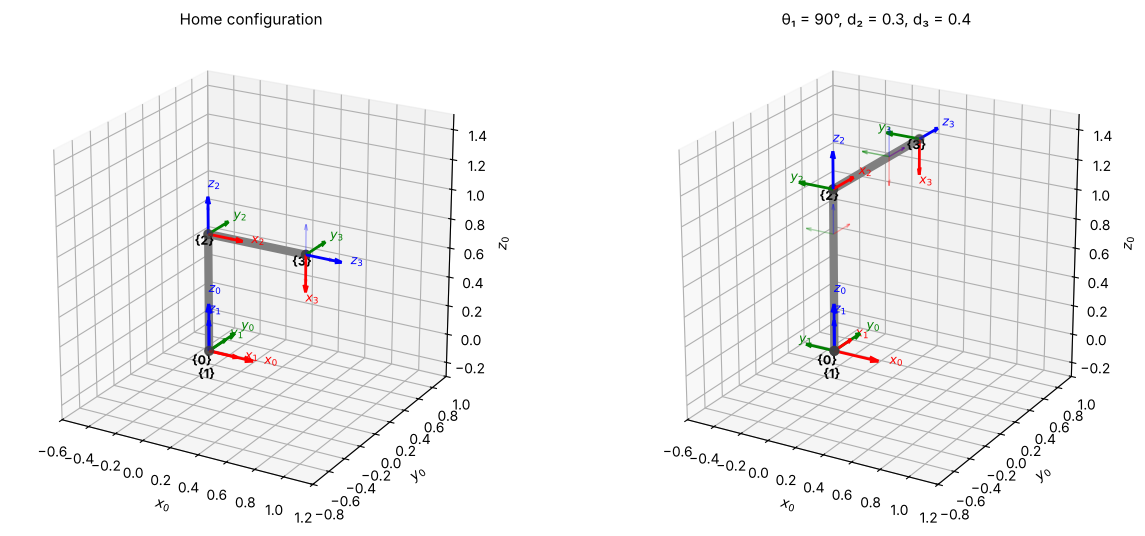

In [18]:
robot_rpp = Robot('Example 3: RPP cylindrical robot',
                  home=[[], [Tr('z', h, 'h')], [Tr('x', a, 'a'), Rt('y', np.pi/2, r'90^\circ')]],
                  joints=[('θ₁', r'\theta_1', 'R', (-180, 180)),
                          ('d₂', 'd_2', 'P', (-0.4, 0.5)),
                          ('d₃', 'd_3', 'P', (-0.3, 0.5))],
                  tool=[])

view_rpp = dict(center=(0.3, 0.1, 0.6), half=0.9, view=(22, -60))
q_test = [np.radians(-35), 0.2, 0.3]
print('Robot.fk matches fk_rpp:', np.allclose(robot_rpp.fk(q_test), fk_rpp(*q_test)))

snapshot(robot_rpp, [np.zeros(3), [np.radians(90), 0.3, 0.4]],
         ['Home configuration', 'θ₁ = 90°, d₂ = 0.3, d₃ = 0.4'], **view_rpp)

In [19]:
explore(robot_rpp, **view_rpp)

interactive(children=(IntSlider(value=6, description='factors', max=6), FloatSlider(value=0.0, description='θ₁…

> **Key Takeaways — Section 5.6**
> - A prismatic joint post-multiplies by $\mathrm{Trans}_{z,d_i}$ instead of $\mathrm{Rot}_{z,\theta_i}$ — that is the only change.
> - If no tool offset is needed, frame $\{e\}$ can coincide with frame $\{n\}$: $\mathbf{T}_e^n = \mathbf{I}$.
> - RPP robot: $o_e = ((a+d_3)c_1, (a+d_3)s_1, h+d_2)$ — cylindrical coordinates.

## 5.7  Example 4 — SCARA Robot (RRPR)

The SCARA (Selective Compliance Assembly Robot Arm) is the standard pick-and-place
robot: two vertical revolute joints ($\theta_1$, $\theta_2$) move the arm in a horizontal
plane, a prismatic quill ($d_3$) moves the tool **down**, and a final revolute joint
($\theta_4$) rolls the tool. Parameters: shoulder height $h$, link lengths $L_1$, $L_2$,
and tool length $d_e$.

**Step 1 — Frames.** $z_1$ and $z_2$ point up along the two vertical revolute axes.
The quill moves downward, so we flip the frame with $\mathrm{Rot}_{x,180^\circ}$: $z_3$
and $z_4$ point **down**. Frame $\{e\}$ is at the tool tip, $d_e$ further along $z_4$.


<p align="center"><img src="Fig5-10_SCARA.png" width="600"></p>

<p align="center"><i>Figure 5.10 — Example 4 (Lecture 10): SCARA frames at home. Frames {3}, {4}, {e} point z down.</i></p>

**Step 2 — Home configuration and joint motion.**

$$\mathbf{T}_1^0(0) = \mathrm{Trans}_{z,h},\quad
\mathbf{T}_2^1(0) = \mathrm{Trans}_{x,L_1},\quad
\mathbf{T}_3^2(0) = \mathrm{Trans}_{x,L_2}\,\mathrm{Rot}_{x,180^\circ},\quad
\mathbf{T}_4^3(0) = \mathbf{I}_{4\times4},\quad
\mathbf{T}_e^4 = \mathrm{Trans}_{z,d_e}$$

$$\begin{aligned}
\mathbf{T}_1^0(\theta_1) &= \mathrm{Trans}_{z,h}\,\mathrm{Rot}_{z,\theta_1}, &
\mathbf{T}_2^1(\theta_2) &= \mathrm{Trans}_{x,L_1}\,\mathrm{Rot}_{z,\theta_2},\\
\mathbf{T}_3^2(d_3) &= \mathrm{Trans}_{x,L_2}\,\mathrm{Rot}_{x,180^\circ}\,\mathrm{Trans}_{z,d_3}\ \ \text{(prismatic)}, &
\mathbf{T}_4^3(\theta_4) &= \mathrm{Rot}_{z,\theta_4}.
\end{aligned}$$

**Step 3 — Multiply.**

$$\mathbf{T}_e^0 = \mathbf{T}_1^0\,\mathbf{T}_2^1\,\mathbf{T}_3^2\,\mathbf{T}_4^3\,\mathbf{T}_e^4$$

In [20]:
h, L1, L2, de = 0.8, 0.8, 0.6, 0.15


def fk_scara(th1, th2, d3, th4, h=0.8, L1=0.8, L2=0.6, de=0.15):
    # Step 2 — home configuration (all joint variables = 0)
    T10_0 = Trans('z', h)                                   # T_1^0(0)
    T21_0 = Trans('x', L1)                                  # T_2^1(0)
    T32_0 = Trans('x', L2) @ Rot('x', np.radians(180))      # T_3^2(0)
    T43_0 = np.eye(4)                                       # T_4^3(0)
    Te4   = Trans('z', de)                                  # T_e^4 (constant)
    # Step 2 — joint motion
    T10 = T10_0 @ Rot('z', th1)             # revolute
    T21 = T21_0 @ Rot('z', th2)             # revolute
    T32 = T32_0 @ Trans('z', d3)            # prismatic
    T43 = T43_0 @ Rot('z', th4)             # revolute
    # Step 3
    return T10 @ T21 @ T32 @ T43 @ Te4


show(fk_scara(np.radians(90), np.radians(-90), 0, 0), 'T_e^0 at (θ1, θ2, d3, θ4) = (90°, -90°, 0, 0)')

T_e^0 at (θ1, θ2, d3, θ4) = (90°, -90°, 0, 0) =
[[ 1.    0.    0.    0.6 ]
 [ 0.   -1.    0.    0.8 ]
 [ 0.    0.   -1.    0.65]
 [ 0.    0.    0.    1.  ]]


In [21]:
t1, t2, d3, t4 = sp.symbols('theta_1 theta_2 d_3 theta_4', real=True)
hs, l1, l2, des = sp.symbols('h L_1 L_2 d_e', real=True)
Te0_scara = sp.simplify(sTrans('z', hs) * sRot('z', t1) * sTrans('x', l1) * sRot('z', t2)
                        * sTrans('x', l2) * sRot('x', sp.pi) * sTrans('z', d3)
                        * sRot('z', t4) * sTrans('z', des))
show_sym(Te0_scara, r'\mathbf{T}_e^0')

<IPython.core.display.Math object>

Reading the result:

- **Position:** $o_e = \big(L_1c_1 + L_2c_{12},\ L_1s_1 + L_2s_{12},\ h - d_3 - d_e\big)$.
  The $x,y$ part is the planar 2R arm from Example 1; the height only depends on the
  quill. Positive $d_3$ lowers the tool because $z_3$ points down.
- **Orientation:** with $\varphi = \theta_1 + \theta_2 - \theta_4$,
  $\mathbf{R}_e^0 = \begin{bmatrix}\cos\varphi & \sin\varphi & 0\\ \sin\varphi & -\cos\varphi & 0\\ 0&0&-1\end{bmatrix}$:
  the tool always points straight down ($z_e = -z_0$) and can only spin about the
  vertical. $\theta_4$ enters with a minus sign because $z_4$ points down, so a positive
  $\theta_4$ turns the tool clockwise when seen from above.

Robot.fk matches fk_scara: True


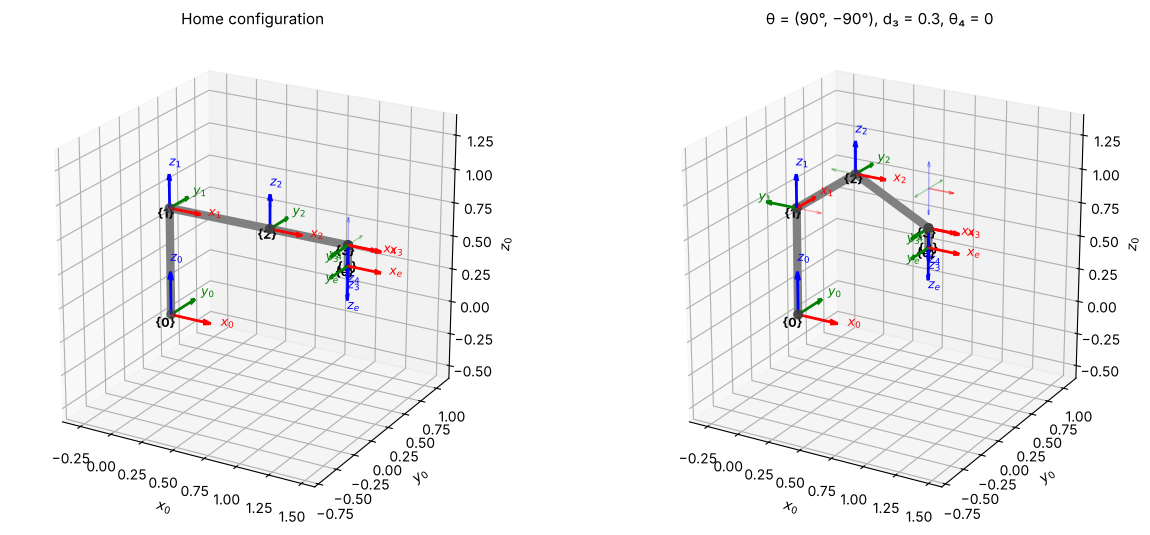

In [22]:
robot_scara = Robot('Example 4: SCARA (RRPR)',
                    home=[[Tr('z', h, 'h')], [Tr('x', L1, 'L_1')],
                          [Tr('x', L2, 'L_2'), Rt('x', np.pi, r'180^\circ')], []],
                    joints=[('θ₁', r'\theta_1', 'R', (-180, 180)),
                            ('θ₂', r'\theta_2', 'R', (-180, 180)),
                            ('d₃', 'd_3', 'P', (0, 0.6)),
                            ('θ₄', r'\theta_4', 'R', (-180, 180))],
                    tool=[Tr('z', de, 'd_e')])

view_scara = dict(center=(0.6, 0.2, 0.4), half=1.0, view=(22, -60))
q_test = [np.radians(30), np.radians(45), 0.25, np.radians(-60)]
print('Robot.fk matches fk_scara:', np.allclose(robot_scara.fk(q_test), fk_scara(*q_test)))

snapshot(robot_scara, [np.zeros(4), [np.radians(90), np.radians(-90), 0.3, 0]],
         ['Home configuration', 'θ = (90°, −90°), d₃ = 0.3, θ₄ = 0'], **view_scara)

In [23]:
explore(robot_scara, **view_scara)

interactive(children=(IntSlider(value=9, description='factors', max=9), FloatSlider(value=0.0, description='θ₁…

> **Key Takeaways — Section 5.7**
> - A fixed $\mathrm{Rot}_{x,180^\circ}$ in $\mathbf{T}_3^2(0)$ flips $z$ downward so the quill's positive direction is "down".
> - SCARA: $o_e = (L_1c_1 + L_2c_{12},\ L_1s_1 + L_2s_{12},\ h-d_3-d_e)$; the tool always points down with yaw $\theta_1+\theta_2-\theta_4$.

## 5.8  Example 5 — UR5e from a MuJoCo Model

The Universal Robots **UR5e** is a 6-DOF industrial arm. Its geometry here comes from
the MuJoCo Menagerie model `universal_robots_ur5e/ur5e.xml`, the same kind of MJCF file
you met in Chapter 3. The MJCF uses its own body frames (four of its joint axes are
along a local $y$), so we **re-assign the frames with our Step 1 recipe**: $z_i$ along
joint $i$, pointing the same way as the MJCF joint axis, so that $\theta_i$ equals MuJoCo's
`qpos[i]`. Frame $\{0\}$ is the MuJoCo world frame; at home the arm reaches along $-x_0$.

Parameters (m): $d_1 = 0.163$, $a_2 = 0.425$, $a_3 = 0.392$, $d_4 = 0.134$,
$d_5 = 0.100$, $d_6 = 0.100$.

**Step 1 — Frames at home ($\theta = 0$).**

| Frame | MJCF joint / site | $o_i$ in frame $\{0\}$ | $z_i$ |
|---|---|---|---|
| 1 | `shoulder_pan_joint` | $(0,\ 0,\ 0.163)$ | $+z_0$ |
| 2 | `shoulder_lift_joint` | $(0,\ 0,\ 0.163)$ | $-y_0$ |
| 3 | `elbow_joint` | $(-0.425,\ 0,\ 0.163)$ | $-y_0$ |
| 4 | `wrist_1_joint` | $(-0.817,\ 0,\ 0.163)$ | $-y_0$ |
| 5 | `wrist_2_joint` | $(-0.817,\ -0.134,\ 0.163)$ | $-z_0$ |
| 6 | `wrist_3_joint` | $(-0.817,\ -0.134,\ 0.063)$ | $-y_0$ |
| e | `attachment_site` | $(-0.817,\ -0.234,\ 0.063)$ | $-y_0$ |

Axes 2, 3 and 4 are parallel, and axis 2 meets axis 1, so we may slide $o_2$ along its
axis until $o_2 = o_1$. The small sideways offsets in the MJCF ($0.138$, $-0.131$,
$0.127$ m) then collapse into the single offset $d_4 = 0.134$ m.


<p align="center"><img src="Fig5-11_UR5e.png" width="760"></p>

<p align="center"><i>Figure 5.11 — Example 5: UR5e at home with frames re-assigned so z<sub>i</sub> lies along joint i.</i></p>

**Step 2 — Home configuration and joint motion** (all joints revolute):

$$\begin{aligned}
\mathbf{T}_1^0(0) &= \mathrm{Trans}_{z,d_1}, &
\mathbf{T}_2^1(0) &= \mathrm{Rot}_{x,90^\circ}, &
\mathbf{T}_3^2(0) &= \mathrm{Trans}_{x,-a_2},\\
\mathbf{T}_4^3(0) &= \mathrm{Trans}_{x,-a_3}, &
\mathbf{T}_5^4(0) &= \mathrm{Trans}_{z,d_4}\,\mathrm{Rot}_{x,90^\circ}, &
\mathbf{T}_6^5(0) &= \mathrm{Trans}_{z,d_5}\,\mathrm{Rot}_{x,-90^\circ},\\
\mathbf{T}_e^6 &= \mathrm{Trans}_{z,d_6}, &
\mathbf{T}_i^{i-1}(\theta_i) &= \mathbf{T}_i^{i-1}(0)\,\mathrm{Rot}_{z,\theta_i}.
\end{aligned}$$

**Step 3 — Multiply.** $\mathbf{T}_e^0 = \mathbf{T}_1^0\mathbf{T}_2^1\mathbf{T}_3^2\mathbf{T}_4^3\mathbf{T}_5^4\mathbf{T}_6^5\mathbf{T}_e^6$.

This chain was checked against MuJoCo's own forward kinematics
(`data.site_xpos`, `data.site_xmat` of `attachment_site`) at 500 random joint vectors:
position and orientation agree to about $10^{-15}$.

In [24]:
d1, a2, a3, d4, d5, d6 = 0.163, 0.425, 0.392, 0.134, 0.100, 0.100

# Step 2 — home configuration
T_home = [Trans('z', d1),                                 # T_1^0(0)
          Rot('x', np.radians(90)),                       # T_2^1(0)
          Trans('x', -a2),                                # T_3^2(0)
          Trans('x', -a3),                                # T_4^3(0)
          Trans('z', d4) @ Rot('x', np.radians(90)),      # T_5^4(0)
          Trans('z', d5) @ Rot('x', np.radians(-90))]     # T_6^5(0)
Te6 = Trans('z', d6)


def fk_ur5e(q):
    T = np.eye(4)
    for Ti_home, qi in zip(T_home, q):
        T = T @ Ti_home @ Rot('z', qi)      # revolute joint i
    return T @ Te6                          # Step 3


q_up = np.radians([0, -90, 0, -90, 0, 0])
show(fk_ur5e(np.zeros(6)), 'T_e^0 at home (q = 0)')
print()
show(fk_ur5e(q_up), "T_e^0 at the 'upright' pose (0, -90°, 0, -90°, 0, 0)")

T_e^0 at home (q = 0) =
[[ 1.     0.     0.    -0.817]
 [ 0.     0.    -1.    -0.234]
 [ 0.     1.     0.     0.063]
 [ 0.     0.     0.     1.   ]]

T_e^0 at the 'upright' pose (0, -90°, 0, -90°, 0, 0) =
[[-1.     0.     0.     0.   ]
 [ 0.     0.    -1.    -0.234]
 [ 0.    -1.     0.     1.08 ]
 [ 0.     0.     0.     1.   ]]


In [25]:
# Closed-form gripper position (group the terms by link parameter, then simplify)
q = sp.symbols('theta_1:7', real=True)
D1, A2, A3, D4, D5, D6 = sp.symbols('d_1 a_2 a_3 d_4 d_5 d_6', real=True)
sT_home = [sTrans('z', D1), sRot('x', sp.pi/2), sTrans('x', -A2), sTrans('x', -A3),
           sTrans('z', D4) * sRot('x', sp.pi/2), sTrans('z', D5) * sRot('x', -sp.pi/2)]

Te0_ur = sp.eye(4)
for Ti_home, qi in zip(sT_home, q):
    Te0_ur = Te0_ur * Ti_home * sRot('z', qi)
Te0_ur = Te0_ur * sTrans('z', D6)

o_e = sp.Matrix([sp.trigsimp(sp.collect(sp.expand(Te0_ur[i, 3]), [D1, A2, A3, D4, D5, D6]))
                 for i in range(3)])
show_sym(o_e, r'o_e')

<IPython.core.display.Math object>

The closed form is long, but notice the structure: $\theta_2$, $\theta_3$, $\theta_4$
only appear through the sums $\theta_{23} = \theta_2+\theta_3$ and
$\theta_{234} = \theta_2+\theta_3+\theta_4$ — the hallmark of three parallel joint axes
(compare the $\theta_{12}$ terms of the planar 2R arm). $\theta_6$ does not appear at all:
the last joint only rolls the gripper about its own axis. In practice nobody multiplies
this out by hand — the three-step procedure plus a computer is the whole point.

Robot.fk matches fk_ur5e: True


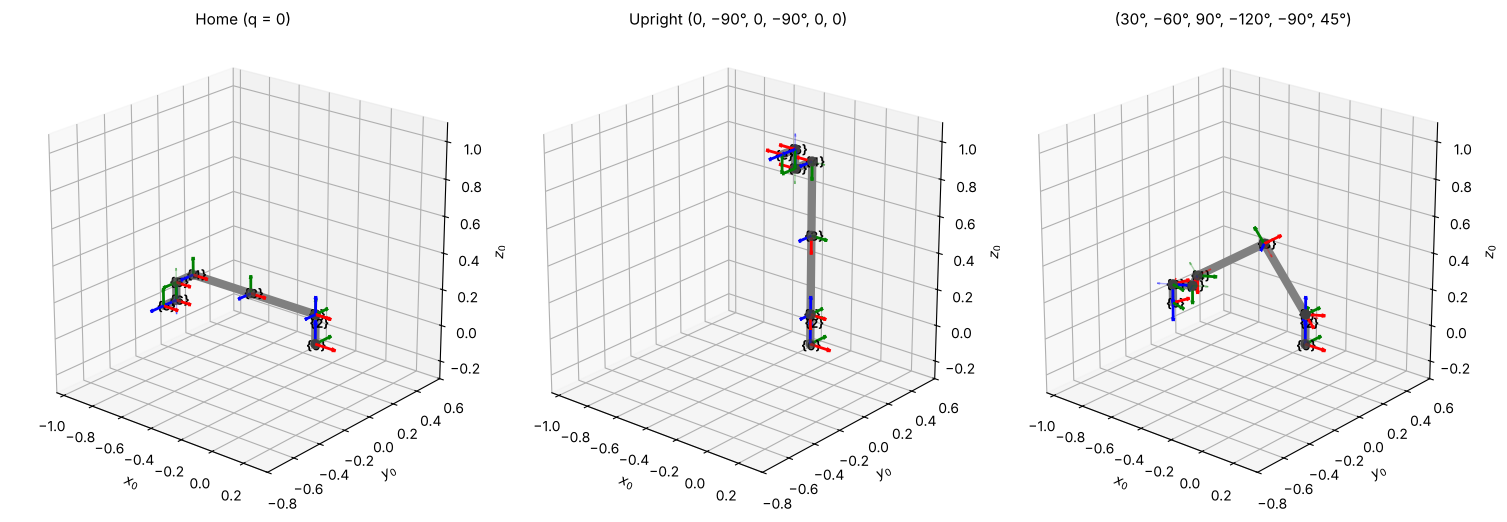

In [26]:
robot_ur5e = Robot('Example 5: UR5e (from MJCF)',
                   home=[[Tr('z', d1, 'd_1')],
                         [Rt('x', np.pi/2, r'90^\circ')],
                         [Tr('x', -a2, '-a_2')],
                         [Tr('x', -a3, '-a_3')],
                         [Tr('z', d4, 'd_4'), Rt('x', np.pi/2, r'90^\circ')],
                         [Tr('z', d5, 'd_5'), Rt('x', -np.pi/2, r'-90^\circ')]],
                   joints=[(f'θ{s}', rf'\theta_{i}', 'R', (-180, 180))
                           for i, s in zip(range(1, 7), '₁₂₃₄₅₆')],
                   tool=[Tr('z', d6, 'd_6')])

view_ur5e = dict(center=(-0.35, -0.1, 0.4), half=0.7, view=(22, -50), scale=0.1, axis_labels=False)
q_test = np.radians([30, -60, 90, -120, -90, 45])
print('Robot.fk matches fk_ur5e:', np.allclose(robot_ur5e.fk(q_test), fk_ur5e(q_test)))

snapshot(robot_ur5e, [np.zeros(6), q_up, q_test],
         ['Home (q = 0)', 'Upright (0, −90°, 0, −90°, 0, 0)', '(30°, −60°, 90°, −120°, −90°, 45°)'],
         figsize=(15, 5.5), **view_ur5e)

In [27]:
explore(robot_ur5e, figsize=(7.5, 7), **view_ur5e)

interactive(children=(IntSlider(value=15, description='factors', max=15), FloatSlider(value=0.0, description='…

> **Key Takeaways — Section 5.8**
> - The same three steps handle a real 6-DOF industrial arm; the only work is Step 1 (choosing frames) and Step 2 (writing the home transforms).
> - A robot model file (MJCF, URDF) gives the geometry, but you may re-assign frames to follow our convention — the gripper pose $\mathbf{T}_e^0$ does not change.
> - Parallel joint axes show up as angle sums ($\theta_{23}$, $\theta_{234}$) in the closed form.

## 5.9  The FK Frame Animator and Chapter Summary

The **FK Frame Animator** (`Ch5 FK Frame Animator.html`, in the same folder as this
notebook) shows all five examples of this chapter as a 3D model you can orbit with the
mouse. It has two modes:

- **Joint motion:** drag the joint sliders (or press *Animate joints*) and watch every
  frame ride on its link. The live $\mathbf{T}_e^0$ is shown next to the closed-form
  position, so you can check your own derivations.
- **Step through product:** the factors of $\mathbf{T}_e^0$ are applied one at a time,
  each one moving the frame along or about its *current* axes — the animated version of
  the `factors` slider used in this notebook.

Run the cell below to open it in your web browser.

In [ ]:
from pathlib import Path
import webbrowser

animator = Path('Ch5 FK Frame Animator.html').resolve()
if animator.exists():
    webbrowser.open(animator.as_uri())
    print('Opened', animator)
else:
    print('Put "Ch5 FK Frame Animator.html" in the same folder as this notebook.')

> **Chapter 5 Summary**
> - An HTM $\mathbf{T}_C^A$ stores the pose of frame $\{C\}$ relative to $\{A\}$; its columns are $x_C$, $y_C$, $z_C$ and $o_C$ expressed in $\{A\}$.
> - Six basic HTMs ($\mathrm{Trans}_{x,y,z}$, $\mathrm{Rot}_{x,y,z}$) build every link transform. A product of them is read left to right, each move about the **current** axes.
> - **Forward kinematics in three steps:**
>   1. Frames: $\{0\}$ on the ground, $\{i\}$ on link $i$ with $z_i$ along joint $i$, $\{e\}$ at the gripper.
>   2. $\mathbf{T}_i^{i-1}(\theta_i) = \mathbf{T}_i^{i-1}(0)\,\mathrm{Rot}_{z,\theta_i}$ (revolute) or $\mathbf{T}_i^{i-1}(0)\,\mathrm{Trans}_{z,\theta_i}$ (prismatic).
>   3. $\mathbf{T}_e^0 = \mathbf{T}_1^0\,\mathbf{T}_2^1\cdots\mathbf{T}_n^{n-1}\,\mathbf{T}_e^n$.
> - Forward kinematics always has exactly **one** answer. The reverse problem — find the joint variables that put the gripper at a desired pose — is **inverse kinematics**, and it is much harder.

| Example | Joints | Gripper position $o_e$ |
|---|---|---|
| Planar 2R | RR | $(L_1c_1 + L_2c_{12},\ L_1s_1 + L_2s_{12},\ 0)$ |
| Spherical wrist | RRR | $L\,(c_1s_2,\ s_1s_2,\ c_2)$ |
| Cylindrical | RPP | $\big((a+d_3)c_1,\ (a+d_3)s_1,\ h+d_2\big)$ |
| SCARA | RRPR | $(L_1c_1 + L_2c_{12},\ L_1s_1 + L_2s_{12},\ h-d_3-d_e)$ |
| UR5e | RRRRRR | see Section 5.8 |